In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score,roc_curve, accuracy_score, confusion_matrix
from catboost import CatBoostClassifier, Pool

In [2]:
df_train = pd.read_csv("./playground-series-s6e9/train.csv")
df_target_train = df_train["Will_Buy_EV"]
df_train =df_train.drop(columns=["Will_Buy_EV"])
df_test = pd.read_csv("./playground-series-s6e9/test.csv")
df_target = pd.read_csv("./playground-series-s6e9/sample_submission.csv")

In [3]:
df_train.head()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low


In [4]:
df_train.dtypes

id                               int64
Age                              int64
Annual_Income_USD              float64
Daily_Commute_km               float64
Number_of_Cars_Owned             int64
Charging_Stations_Near_Home      int64
Charging_Stations_Near_Work      int64
Environmental_Concern_Level    float64
Gender                          object
City_Type                       object
Current_Car_Type                object
Home_Charging_Possible          object
Subsidy_Available               object
Range_Anxiety_Level             object
dtype: object

In [5]:
df_test.head()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level
0,668665,61,67725.0,16.9,2,7,4,4.0,Male,Suburban,Sedan,Yes,No,Low
1,668666,42,152835.0,41.9,2,9,9,4.0,Male,Urban,SUV,No,No,Low
2,668667,68,86877.0,53.3,1,10,11,4.0,Female,Urban,Sedan,No,No,Low
3,668668,39,46794.0,34.1,2,4,8,4.0,Female,Suburban,Sedan,Yes,No,Low
4,668669,55,112172.0,57.2,1,6,4,1.0,Female,Suburban,Sedan,Yes,Yes,Low


In [6]:
df_target.head()

,id,Will_Buy_EV
0,668665,0.174645
1,668666,0.174645
2,668667,0.174645
3,668668,0.174645
4,668669,0.174645


In [3]:
cat_features = [8,9,10,11,12,13]

In [4]:
train_pool = Pool(data=df_train, label = df_target_train, cat_features=cat_features)
test_pool = Pool(data=df_test, cat_features=cat_features)

In [16]:
model = CatBoostClassifier(iterations=5000, learning_rate=0.5, depth=6, verbose=100)

In [ ]:
model.fit(train_pool)

0:	learn: 0.2845714	total: 252ms	remaining: 20m 58s


In [15]:
y_predict = model.predict(df_test)
y_pred_proba = model.predict_proba(df_test)[:,1] 
pred_df = pd.DataFrame({
    "id": df_test["id"],
    "prediction_proba": y_pred_proba
})
pred_df.to_csv("predictions.csv", index=False)

In [12]:


pred_df.head()

,id,prediction_proba
0,668665,0.013108
1,668666,0.018091
2,668667,0.004962
3,668668,0.003093
4,668669,0.022633


In [18]:

# df_target["Will_Buy_EV"] = (df_target["Will_Buy_EV"].astype(int))

y_true = df_target["Will_Buy_EV"].astype(int)

In [19]:
y_true.value_counts()

Will_Buy_EV
0    286571
Name: count, dtype: int64

C:\Users\P.BHUVANESH CHOWDARY\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
C:\Users\P.BHUVANESH CHOWDARY\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1201: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


ROC-AUC: nan


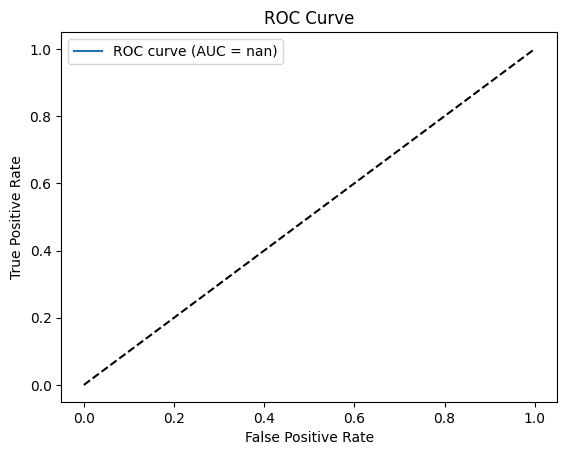

In [17]:
import matplotlib.pyplot as plt
auc = roc_auc_score(y_true, y_pred_proba)
print("ROC-AUC:", auc)

fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba)

plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.2f})")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()